# AA3 · Parcial II · Cuaderno 1: Recurrentes
**Alumno:** Santiago Romo Rubio
**Datos:** QQQ (Invesco QQQ Trust, réplica del Nasdaq-100), velas diarias de 5 años de Yahoo Finanzas

Pronóstico del cierre con una **GRU apilada** (Práctica 3, parte A, Bloque 6), comparada contra la línea base «mañana = hoy», y pronóstico de los próximos 30 días hábiles.

> **Recordatorio ético:** es un ejercicio académico, no una recomendación de inversión.

## 1. Datos
Entorno, formulario, descarga y preparación con las reglas de los Bloques 2 y 3 de la práctica: **división cronológica** 70/15/15, **normalización solo con el entrenamiento** y **ventanas** de 30 días con horizonte de 1 día. `period`, `interval`, `horizonte` y `ventana` quedan fijos, igual que en la práctica.

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
import warnings

warnings.filterwarnings("ignore", message="RNN module weights")  # aviso de cuDNN con PyTorch, no afecta el resultado

# yfinance no viene en Colab; se instala si falta
if importlib.util.find_spec("yfinance") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "yfinance"])

# yfinance antes que torch y keras (en Colab la descarga falla si se importa después)
import yfinance as yf

os.environ["KERAS_BACKEND"] = "torch"
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print(f"Python {sys.version.split()[0]} · Keras {keras.__version__} · backend {keras.backend.backend()} · yfinance {yf.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no disponible'}")

Python 3.11.16 · Keras 3.15.1 · backend torch · yfinance 1.7.0
GPU: NVIDIA GeForce GTX 1660 SUPER


In [2]:
# @title Seleccione la serie { run: "auto" }
ticker = "QQQ"  # @param {type:"string"}
usar_volumen = False  # @param {type:"boolean"}

assert ticker.upper() != "ALC", "El ticker debe ser distinto de ALC"

# Fijos, igual que en la práctica
period, interval, horizonte, ventana, batch_size = "5y", "1d", 1, 30, 32
pasos_futuro = 30
variables = ["Close", "Volume"] if usar_volumen else ["Close"]
print(f"Serie: {ticker} · {period} · {interval} · horizonte {horizonte} · ventana {ventana} · variables {variables}")

Serie: QQQ · 5y · 1d · horizonte 1 · ventana 30 · variables ['Close']


**Descarga.** Se descarta la última vela porque puede estar en formación. Si Yahoo falla, se usa el respaldo local que deja la última descarga exitosa.

QQQ: 1253 velas (2021-11-08 → 2026-11-04) [origen: Yahoo Finanzas]


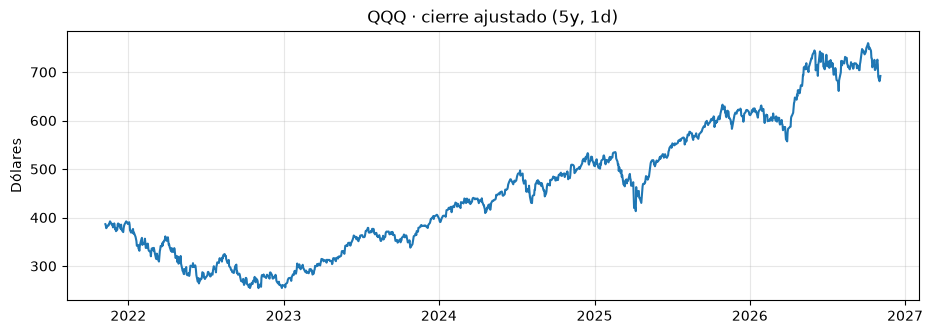

In [3]:
os.makedirs("datos", exist_ok=True)
yf.set_tz_cache_location(os.path.abspath("datos/.yf_cache"))
respaldo = f"datos/respaldo_{ticker.replace('^', '')}_{period}_{interval}.csv"
try:
    df = yf.download(ticker, period=period, interval=interval, multi_level_index=False, auto_adjust=True, progress=False)
    df = df.dropna().copy().iloc[:-1]
    if df.empty:
        raise ValueError("la descarga llegó vacía")
    df.to_csv(respaldo)
    origen = "Yahoo Finanzas"
except Exception as error:
    print(f"AVISO: no se pudo descargar ({error}). Se usa el respaldo local.")
    df = pd.read_csv(respaldo, index_col=0, parse_dates=True)
    origen = respaldo
print(f"{ticker}: {len(df)} velas ({df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d}) [origen: {origen}]")

plt.figure(figsize=(11, 3.5))
plt.plot(df.index, df["Close"], color="tab:blue")
plt.title(f"{ticker} · cierre ajustado ({period}, {interval})")
plt.ylabel("Dólares")
plt.show()

**Preparación.** La media y la desviación estándar salen **solo del entrenamiento**; con ellas se normalizan también validación y prueba, para que el modelo no vea información del futuro.

In [4]:
datos = df[variables].copy()
if usar_volumen:
    datos["Volume"] = np.log1p(datos["Volume"])
raw_data = datos.values.astype("float32")
fechas = datos.index
n_variables = raw_data.shape[1]

# División cronológica 70 / 15 / 15
num_train = int(0.70 * len(raw_data))
num_val = int(0.15 * len(raw_data))
num_test = len(raw_data) - num_train - num_val

# Normalización SOLO con el entrenamiento (sin fuga de información)
media = raw_data[:num_train].mean(axis=0)
std = raw_data[:num_train].std(axis=0)
data_norm = (raw_data - media) / std
media_close, std_close = media[0], std[0]

# Ventanas: 30 días de entrada → cierre del día siguiente
delay = ventana + horizonte - 1
objetivo = data_norm[:, 0]


def crear_dataset(inicio, fin, mezclar=False):
    return keras.utils.timeseries_dataset_from_array(
        data_norm[:-horizonte],
        targets=objetivo[delay:],
        sequence_length=ventana,
        batch_size=batch_size,
        shuffle=mezclar,
        seed=SEED,
        start_index=inicio,
        end_index=fin,
    )


train_ds = crear_dataset(0, num_train - horizonte, mezclar=True)
val_ds = crear_dataset(num_train, num_train + num_val - horizonte)
test_ds = crear_dataset(num_train + num_val, None)

print(f"Entrenamiento: {num_train} ({fechas[0]:%Y-%m-%d} → {fechas[num_train - 1]:%Y-%m-%d})")
print(f"Validación:    {num_val} ({fechas[num_train]:%Y-%m-%d} → {fechas[num_train + num_val - 1]:%Y-%m-%d})")
print(f"Prueba:        {num_test} ({fechas[num_train + num_val]:%Y-%m-%d} → {fechas[-1]:%Y-%m-%d})")
print(f"Estadísticos del entrenamiento (cierre): media {media_close:.2f} · desviación {std_close:.2f}")
min_tr, max_tr = data_norm[:num_train, 0].min(), data_norm[:num_train, 0].max()
fuera = np.mean((data_norm[num_train + num_val :, 0] < min_tr) | (data_norm[num_train + num_val :, 0] > max_tr)) * 100
print(f"Prueba fuera del rango de entrenamiento: {fuera:.1f} %")

muestras, objetivos = next(iter(test_ds))
print(f"Forma de un lote: entradas {tuple(muestras.shape)} · objetivos {tuple(objetivos.shape)}")

Entrenamiento: 877 (2021-11-08 → 2025-05-07)
Validación:    187 (2025-05-08 → 2026-02-04)
Prueba:        189 (2026-02-05 → 2026-11-04)
Estadísticos del entrenamiento (cierre): media 379.97 · desviación 79.04
Prueba fuera del rango de entrenamiento: 100.0 %


Forma de un lote: entradas (32, 30, 1) · objetivos (32,)


## 2. Línea base
«Mañana = hoy» (Bloque 4): el pronóstico del cierre de mañana es el último cierre de la ventana. Los errores se reportan en dólares.

In [5]:
def evaluar_linea_base(dataset, metrica="mae"):
    error_total, n = 0.0, 0
    for muestras, objetivos in dataset:
        error = muestras[:, -1, 0].numpy() - objetivos.numpy()
        error_total += (np.abs(error) if metrica == "mae" else error**2).sum()
        n += objetivos.shape[0]
    promedio = error_total / n
    return (promedio if metrica == "mae" else np.sqrt(promedio)) * std_close


mae_base_val = evaluar_linea_base(val_ds)
mae_base_test = evaluar_linea_base(test_ds)
rmse_base_test = evaluar_linea_base(test_ds, metrica="rmse")
print(f"Línea base «mañana = hoy» · MAE val {mae_base_val:.3f} · MAE prueba {mae_base_test:.3f} · RMSE prueba {rmse_base_test:.3f}")

Línea base «mañana = hoy» · MAE val 4.225 · MAE prueba 7.465 · RMSE prueba 9.681


## 3. Modelo
**GRU apilada** del Bloque 6: `GRU(32, return_sequences=True)` → `GRU(32)` → `Dense(1)`. Mismo optimizador (RMSprop), pérdida (MSE), hasta 50 épocas y `EarlyStopping` con paciencia 8 que en la práctica.

**Por qué la elegí.** En la Parte 1 de la práctica corrí las cuatro recurrentes del Bloque 6 con QQQ:

| Recurrente (QQQ, sin volumen) | MAE prueba | RMSE prueba |
|---|---|---|
| **GRU apilada** | **48.26** | **54.15** |
| LSTM | 59.33 | 67.41 |
| LSTM bidireccional | 64.79 | 72.86 |
| LSTM + *dropout* recurrente | 103.00 | 112.63 |

- Fue la **mejor recurrente** en prueba, aunque ninguna le ganó a la línea base (7.07).
- La **bidireccional** no tiene sentido para pronosticar: la LSTM que lee hacia atrás termina en el día más antiguo de la ventana, el menos útil para predecir mañana, y en la práctica fue peor que la LSTM normal.
- El ***dropout* recurrente** fue el peor y unas 7 veces más lento por época, porque pierde la implementación de cuDNN.
- La GRU tiene dos compuertas y un solo estado, y al apilar dos capas la segunda trabaja sobre la secuencia completa de estados de la primera.

Uso `usar_volumen = False` porque en la Parte 1 el volumen empeoró a la GRU apilada (MAE de 48.26 a 56.87) y a casi todos los modelos.

Model: "GRU_apilada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Ventana (InputLayer)            │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GRU_1_secuencia (GRU)           │ (None, 30, 32)         │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GRU_2_ultimo (GRU)              │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Cierre_futuro (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,729 (38.00 KB)

 Trainable params: 9,729 (38.00 KB)

 Non-trainable params: 0 (0.00 B)

Épocas entrenadas: 25 (mejor: 17) · 0.34 s/época


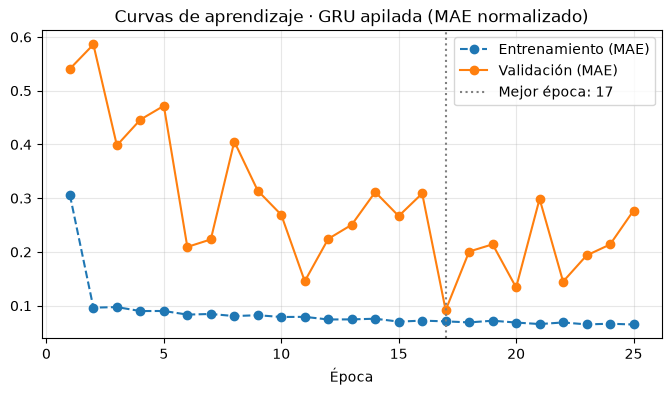

In [6]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(ventana, n_variables), name="Ventana")
x = layers.GRU(32, return_sequences=True, name="GRU_1_secuencia")(inputs)
x = layers.GRU(32, name="GRU_2_ultimo")(x)
outputs = layers.Dense(1, name="Cierre_futuro")(x)
modelo = keras.Model(inputs, outputs, name="GRU_apilada")
modelo.summary()

modelo.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
inicio = time.perf_counter()
historia = modelo.fit(
    train_ds,
    epochs=50,
    validation_data=val_ds,
    shuffle=False,  # train_ds ya viene con las ventanas mezcladas
    verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)],
)
epocas = len(historia.history["loss"])
seg_epoca = (time.perf_counter() - inicio) / epocas
mejor = int(np.argmin(historia.history["val_loss"])) + 1
print(f"Épocas entrenadas: {epocas} (mejor: {mejor}) · {seg_epoca:.2f} s/época")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epocas + 1), historia.history["mae"], "o--", label="Entrenamiento (MAE)")
plt.plot(range(1, epocas + 1), historia.history["val_mae"], "o-", label="Validación (MAE)")
plt.axvline(mejor, color="gray", linestyle=":", label=f"Mejor época: {mejor}")
plt.title("Curvas de aprendizaje · GRU apilada (MAE normalizado)")
plt.xlabel("Época")
plt.legend()
plt.show()

## 4. Resultados
MAE y RMSE de **prueba** en dólares, de la línea base y de la GRU.

In [7]:
mae_val = modelo.evaluate(val_ds, verbose=0)[1] * std_close
mse_test, mae_test = modelo.evaluate(test_ds, verbose=0)
mae_test, rmse_test = mae_test * std_close, np.sqrt(mse_test) * std_close

resultados = pd.DataFrame(
    {
        "MAE val": [float(mae_base_val), float(mae_val)],
        "MAE prueba": [float(mae_base_test), float(mae_test)],
        "RMSE prueba": [float(rmse_base_test), float(rmse_test)],
        "Parámetros": [0, modelo.count_params()],
    },
    index=["Línea base (mañana = hoy)", "GRU apilada"],
)
resultados["MAE vs. línea base (%)"] = (resultados["MAE prueba"] / mae_base_test - 1) * 100
print(f"→ En prueba, la GRU {'SÍ supera' if mae_test < mae_base_test else 'NO supera'} a la línea base.")
resultados.round(3)

→ En prueba, la GRU NO supera a la línea base.


,MAE val,MAE prueba,RMSE prueba,Parámetros,MAE vs. línea base (%)
Línea base (mañana = hoy),4.225,7.465,9.681,0,0.000
GRU apilada,7.244,44.963,48.353,9729,502.333


**Pronóstico de los próximos 30 días hábiles** con `pronosticar_futuro()` y `dibujar_pronostico()` del Bloque 4. Es **recursivo**: cada cierre predicho entra en la ventana del día siguiente.

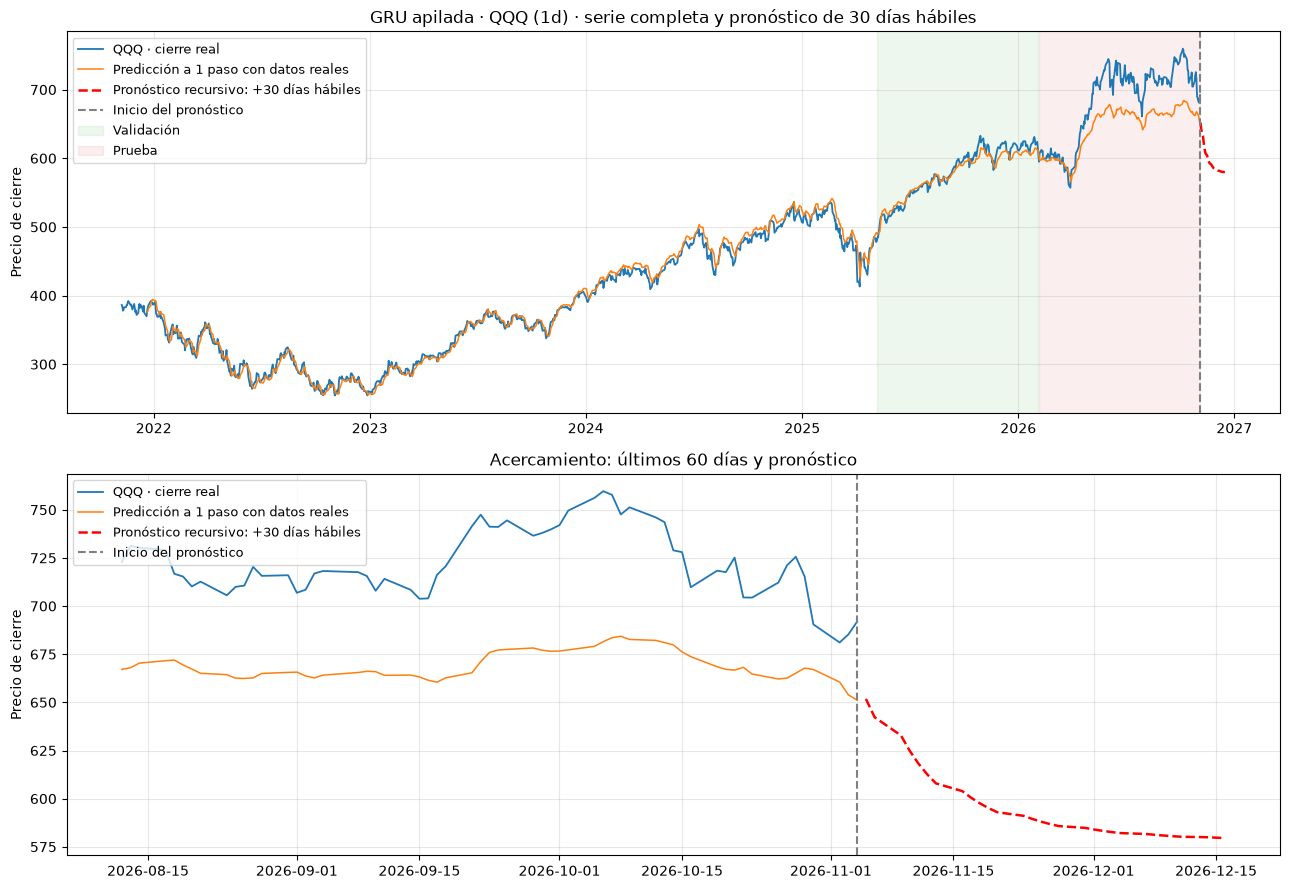

Último cierre conocido (2026-11-04): 691.95
Día 1  (2026-11-05): 651.80 (-5.8 %)
Día 30 (2026-12-16): 579.55 (-16.2 %)
Máximo cierre del entrenamiento: 534.98 · último cierre: 691.95


,Cierre pronosticado,Cambio vs. último cierre (%)
2026-11-05,651.80,-5.80
2026-11-11,618.21,-10.66
2026-11-18,597.62,-13.63
2026-11-25,588.07,-15.01
2026-12-02,583.31,-15.70
2026-12-09,580.85,-16.06
2026-12-16,579.55,-16.24


In [8]:
def fechas_futuras(pasos):
    return pd.bdate_range(fechas[-1] + pd.offsets.BDay(1), periods=pasos)


def pronosticar_futuro(modelo, pasos=None):
    pasos = pasos or pasos_futuro
    n = len(data_norm)
    serie = np.concatenate([data_norm, np.zeros((pasos, n_variables), dtype="float32")])
    if n_variables > 1:
        serie[n:, 1] = data_norm[-ventana:, 1].mean()  # volumen futuro: promedio de la última ventana
    for t in range(n, n + pasos):
        fin = t - horizonte + 1
        serie[t, 0] = modelo.predict(serie[fin - ventana : fin][np.newaxis], verbose=0)[0, 0]
    return serie[n:, 0] * std_close + media_close


def dibujar_pronostico(nombre, pred_real, futuro, pasos_zoom=60):
    pasos = len(futuro)
    cierre = raw_data[:, 0]
    fechas_pred, fechas_fut = fechas[delay:], fechas_futuras(pasos)
    fig, ejes = plt.subplots(2, 1, figsize=(13, 9))
    for eje, desde in [(ejes[0], 0), (ejes[1], len(cierre) - pasos_zoom)]:
        d = max(desde - delay, 0)
        eje.plot(fechas[desde:], cierre[desde:], color="tab:blue", linewidth=1.3, label=f"{ticker} · cierre real")
        eje.plot(fechas_pred[d:], pred_real[d:], color="tab:orange", linewidth=1.1, label=f"Predicción a {horizonte} paso con datos reales")
        eje.plot(fechas_fut, futuro, "--", color="red", linewidth=1.8, label=f"Pronóstico recursivo: +{pasos} días hábiles")
        eje.axvline(fechas[-1], color="gray", linestyle="--", label="Inicio del pronóstico")
        eje.set_ylabel("Precio de cierre")
    ejes[0].axvspan(fechas[num_train], fechas[num_train + num_val - 1], color="tab:green", alpha=0.08, label="Validación")
    ejes[0].axvspan(fechas[num_train + num_val], fechas[-1], color="tab:red", alpha=0.08, label="Prueba")
    ejes[0].set_title(f"{nombre} · {ticker} ({interval}) · serie completa y pronóstico de {pasos} días hábiles")
    ejes[1].set_title(f"Acercamiento: últimos {pasos_zoom} días y pronóstico")
    for eje in ejes:
        eje.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()


pred_real = modelo.predict(crear_dataset(0, None), verbose=0)[:, 0] * std_close + media_close
futuro = pronosticar_futuro(modelo)
dibujar_pronostico("GRU apilada", pred_real, futuro)

fechas_fut = fechas_futuras(pasos_futuro)
cambio = (futuro / raw_data[-1, 0] - 1) * 100
print(f"Último cierre conocido ({fechas[-1]:%Y-%m-%d}): {raw_data[-1, 0]:.2f}")
print(f"Día 1  ({fechas_fut[0]:%Y-%m-%d}): {futuro[0]:.2f} ({cambio[0]:+.1f} %)")
print(f"Día 30 ({fechas_fut[-1]:%Y-%m-%d}): {futuro[-1]:.2f} ({cambio[-1]:+.1f} %)")
print(f"Máximo cierre del entrenamiento: {raw_data[:num_train, 0].max():.2f} · último cierre: {raw_data[-1, 0]:.2f}")
pd.DataFrame({"Cierre pronosticado": futuro.astype(float).round(2), "Cambio vs. último cierre (%)": cambio.astype(float).round(2)}, index=fechas_fut.date).iloc[[0, 4, 9, 14, 19, 24, 29]]

In [9]:
resultados = resultados.round(3)
resultados

,MAE val,MAE prueba,RMSE prueba,Parámetros,MAE vs. línea base (%)
Línea base (mañana = hoy),4.225,7.465,9.681,0,0.000
GRU apilada,7.244,44.963,48.353,9729,502.333


## 5. Conclusión
Antes de responder, los tres diagnósticos de la práctica: el **retraso de un día** y la **exactitud direccional** (Bloque 8), y el **sesgo del pronóstico recursivo** (Bloques 4 y 7).

1) Retraso de un día
   MAE contra el cierre REAL a predecir: 44.963
   MAE contra el ÚLTIMO cierre conocido: 44.028  ← si es mucho menor, el modelo copia el día anterior
   Correlación entre el cambio predicho y el real: +0.205
   Sesgo medio (predicción − real): -44.27 dólares

2) Exactitud direccional en prueba
   GRU apilada:     46.5 %
   Siempre «sube»:  54.1 %
   Moneda al aire:  50.0 %

3) Sesgo del pronóstico recursivo
   Prueba fuera del rango del entrenamiento: 100.0 %
   Último cierre en unidades normalizadas: +3.95 (máximo del entrenamiento: +1.96)
   Pronóstico a 30 días: -16.2 % · línea base (mañana = hoy): +0.0 %


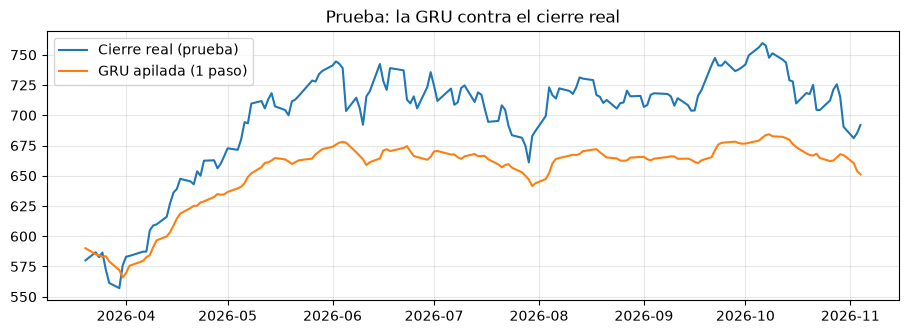

In [10]:
X_test = np.concatenate([x.numpy() for x, _ in test_ds])
y_test = np.concatenate([y.numpy() for _, y in test_ds])
desnorm = lambda v: v * std_close + media_close
real, ultimo = desnorm(y_test), desnorm(X_test[:, -1, 0])
pred = desnorm(modelo.predict(X_test, verbose=0)[:, 0])

print("1) Retraso de un día")
print(f"   MAE contra el cierre REAL a predecir: {np.mean(np.abs(pred - real)):.3f}")
print(f"   MAE contra el ÚLTIMO cierre conocido: {np.mean(np.abs(pred - ultimo)):.3f}  ← si es mucho menor, el modelo copia el día anterior")
print(f"   Correlación entre el cambio predicho y el real: {np.corrcoef(pred - ultimo, real - ultimo)[0, 1]:+.3f}")
print(f"   Sesgo medio (predicción − real): {np.mean(pred - real):+.2f} dólares")

real_sube = real > ultimo
print("\n2) Exactitud direccional en prueba")
print(f"   GRU apilada:     {np.mean((pred > ultimo) == real_sube) * 100:.1f} %")
print(f"   Siempre «sube»:  {real_sube.mean() * 100:.1f} %")
print(f"   Moneda al aire:  50.0 %")

print("\n3) Sesgo del pronóstico recursivo")
print(f"   Prueba fuera del rango del entrenamiento: {fuera:.1f} %")
print(f"   Último cierre en unidades normalizadas: {data_norm[-1, 0]:+.2f} (máximo del entrenamiento: {max_tr:+.2f})")
print(f"   Pronóstico a 30 días: {cambio[-1]:+.1f} % · línea base (mañana = hoy): +0.0 %")

plt.figure(figsize=(11, 3.5))
plt.plot(fechas[-len(real):], real, label="Cierre real (prueba)")
plt.plot(fechas[-len(real):], pred, label="GRU apilada (1 paso)")
plt.title("Prueba: la GRU contra el cierre real")
plt.legend()
plt.show()

**¿QQQ subirá o bajará en los próximos 30 días hábiles?** La GRU apilada pronostica que **baja**: de 691.95 (cierre del 2026-11-04) a 579.55 el 2026-12-16, un **−16.2 %**. **No le tengo confianza a esa conclusión.** La respuesta honesta es «no lo sé», y la mejor estimación disponible es la de la línea base: que el precio se quede cerca de 692. Las razones, con los números de este cuaderno:

1. **No le gana a la línea base.** En prueba, la GRU tiene MAE 44.96 y RMSE 48.35, contra 7.47 y 9.68 de «mañana = hoy»: es un 502 % peor. Si a un día se equivoca seis veces más que copiar el último cierre, a 30 días no hay razón para creerle. El resultado concuerda con la Parte 1 de la práctica, donde la misma GRU tuvo MAE 48.26 con QQQ.
2. **Retraso de un día.** Aquí el síntoma no es que copie el cierre anterior tal cual, sino que lo sigue con un **desplazamiento constante hacia abajo**. Su MAE contra el último cierre conocido (44.03) es casi igual al MAE contra el cierre real (44.96), y su sesgo medio en prueba es de −44.27 dólares: casi todo su error es ese desplazamiento. La correlación entre el cambio que predice y el cambio real es de +0.205, débil.
3. **Exactitud direccional de 46.5 %.** Es peor que una moneda al aire (50 %) y que decir «siempre sube» (54.1 %). El signo del pronóstico, que baja, no tiene respaldo.
4. **Sesgo del pronóstico recursivo.** El 100 % de la prueba queda fuera del rango del entrenamiento. El cierre máximo del entrenamiento fue 534.98 (+1.96 en unidades normalizadas) y el último cierre es 691.95 (+3.95): la red nunca vio precios así. Sus activaciones tanh saturan, así que la salida se queda por debajo del nivel real. El primer día del pronóstico (651.80, −40.15 dólares) repite el mismo sesgo que tiene en prueba (−44.27). Después, cada predicción baja entra en la ventana siguiente y empuja la próxima todavía más abajo, hasta que el pronóstico se estabiliza cerca de 580. La caída de −16.2 % es un **artefacto de la normalización y del pronóstico recursivo**, no una señal del mercado.

**Nivel de confianza: muy bajo, prácticamente nulo**, tanto en la dirección como en la magnitud. Lo que sí deja el cuaderno es una lección de método. Si una serie con tendencia sale del rango del entrenamiento y la red aprende el precio normalizado, va a pronosticar siempre un regreso al rango que conoce. Por eso el Bloque 8 propone predecir el rendimiento en lugar del precio.

> Es un ejercicio académico, no una recomendación de inversión.